### **1. Import libraries**

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

import src.pyTorch as py
import importlib

In [2]:
from sklearn.datasets import make_circles


# Make 1000 samples 
n_samples = 1000

# Create circles
X, y = make_circles(n_samples,
                    noise=0.03, # a little bit of noise to the dots
                    random_state=42) # keep random state so we get the same values

In [3]:
import pandas as pd
print(f"X shape: {X.shape}, y shape: {y.shape}")
circle_df = pd.DataFrame(X, columns=['feature_1', 'feature_2'])
circle_df['Label'] = y
circle_df.head()
print(circle_df['Label'].value_counts())

X shape: (1000, 2), y shape: (1000,)
Label
1    500
0    500
Name: count, dtype: int64


In [4]:
py = importlib.reload(py)

# py.scatter_plot(X, y, title="Circles Dataset")

In [5]:
import torch
import torch.nn as nn
print(type(X), type(y))
x_torch = torch.from_numpy(X).type(torch.float)
y_torch = torch.from_numpy(y).type(torch.long)
print(type(x_torch), type(y_torch))
train_len = int(0.8 * len(x_torch))

# train_features, test_features = x_torch[:train_len], x_torch[train_len:]
# trail_label, test_label = y_torch[:train_len], y_torch[train_len:]

#or by using sklearn built in function
from sklearn.model_selection import train_test_split
train_features, test_features, train_label, test_label = train_test_split(x_torch, y_torch, test_size=0.2, random_state=42)

<class 'numpy.ndarray'> <class 'numpy.ndarray'>
<class 'torch.Tensor'> <class 'torch.Tensor'>


In [6]:
print(len(train_features), len(test_features), len(train_label), len(test_label))
print(train_features.shape, test_features.shape, train_label.shape, test_label.shape)
print(train_features.ndim, test_features.ndim, train_label.ndim, test_label.ndim)

800 200 800 200
torch.Size([800, 2]) torch.Size([200, 2]) torch.Size([800]) torch.Size([200])
2 2 1 1


**Check the device**

In [7]:
device  = "cuda" if torch.cuda.is_available() else "cpu"
device  #in my computer GPU is not supported then CPU are the device

'cpu'

In [8]:
#import the model 
py = importlib.reload(py)
model_one = py.classification_model()
model_one

classification_model(
  (layer1): Linear(in_features=2, out_features=5, bias=True)
  (layer2): Linear(in_features=5, out_features=1, bias=True)
)

In [9]:
model = nn.Sequential(   #this is fast forward technique for intializing the model
    nn.Linear(in_features=2, out_features=5),
    nn.Linear(in_features=5, out_features=1)
)

In [10]:
untrained_pre = model(train_features)

untrained_pre[:5]

tensor([[0.1767],
        [0.1519],
        [0.4673],
        [0.4500],
        [0.4377]], grad_fn=<SliceBackward0>)

### **2. Loss function and Optimizer**

<font color="red">**Loss function**</font> for Classification  is differe from what we ware use for Regression.

In [11]:
#for regression we use Mean square error
#for Classification(Binary) we use Cross Entropy Loss(Binary cross entropy)
#But for Optimizer are similar for both case.

Create or intialize the model cost function and optimizer for further analysis

In [12]:
#ccreate loss function 
loss_fn = nn.BCEWithLogitsLoss()

#Create optimizer
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

In [13]:
py = importlib.reload(py)

py.man_accuracy(train_label, untrained_pre)

'0.00%'

In [14]:
y_logits = model_one(test_features[:5])  #predict the first five elements
y_logits

tensor([[-0.0121],
        [ 0.2557],
        [-0.6268],
        [ 0.1617],
        [-0.4882]], grad_fn=<AddmmBackward0>)

In [15]:
y_predi_prob = torch.sigmoid(y_logits)
y_predi_prob

tensor([[0.4970],
        [0.5636],
        [0.3482],
        [0.5403],
        [0.3803]], grad_fn=<SigmoidBackward0>)

In [16]:
round_output = torch.round(y_predi_prob)
y_predi_full = torch.round(torch.sigmoid(model_one(test_features).to(device)))
y_predi_full[:5], round_output   #They have similar output

(tensor([[0.],
         [1.],
         [0.],
         [1.],
         [0.]], grad_fn=<SliceBackward0>),
 tensor([[0.],
         [1.],
         [0.],
         [1.],
         [0.]], grad_fn=<RoundBackward0>))

In [17]:
print(torch.eq(y_predi_full[:5], round_output)) #torch.eq() method compares the two tesnor element wise and return boolean values
y_predi_full.squeeze().shape, round_output.squeeze().shape  ,test_label[:5]

tensor([[True],
        [True],
        [True],
        [True],
        [True]])


(torch.Size([200]), torch.Size([5]), tensor([1, 0, 1, 0, 1]))

### **3. Building Training loop**

In [18]:
prediction = model_one(test_features.to(device))
prediction.squeeze().shape, test_label.shape

(torch.Size([200]), torch.Size([200]))

In [19]:
py = importlib.reload(py)
torch.manual_seed(42) #it healps for reproducablity

epochs = 100
#if GPU(cuda) avaliable put the data to that(my case not available)
loss_function = []
epoch_value = []

for epoch in range(epochs):    #100 iteration for training the model.
    model_one.train()   
    y_logits = model_one(train_features.to(device)).squeeze()  #forward pass
    loss = loss_fn(y_logits.squeeze(), train_label.type(torch.float32).to(device))           #calculate the loss
    optimizer.zero_grad()                                      #zero the gradients
    loss.backward()                                            #backward pass
    optimizer.step()                                           #update the weights

    #then testing loop
    model_one.eval()       #put the model in evaluation mode
    with torch.inference_mode(): #turn on inference mode (turn off gradients)
        test_logits = model_one(test_features.to(device)).squeeze()  #forward pass(prediction of test dataset)
        test_logits = (torch.sigmoid(test_logits)>=0.5).float()     #turn the logits to probability
        test_loss = loss_fn(test_logits.squeeze(), test_label.type(torch.float32).to(device)) #Calculate the loss funcion of test dataset
        test_acc = py.man_accuracy(test_label.to(device), test_logits.to(device))      #Calculate the accuracy of the model.
    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f} | Test Loss: {test_loss:.5f} | Test Accuracy: {test_acc}")  
    loss_function.append(loss.item())
    epoch_value.append(epoch)

Epoch: 0 | Loss: 0.71529 | Test Loss: 0.76119 | Test Accuracy: 46.00%
Epoch: 10 | Loss: 0.71529 | Test Loss: 0.76119 | Test Accuracy: 46.00%
Epoch: 20 | Loss: 0.71529 | Test Loss: 0.76119 | Test Accuracy: 46.00%
Epoch: 30 | Loss: 0.71529 | Test Loss: 0.76119 | Test Accuracy: 46.00%
Epoch: 40 | Loss: 0.71529 | Test Loss: 0.76119 | Test Accuracy: 46.00%
Epoch: 50 | Loss: 0.71529 | Test Loss: 0.76119 | Test Accuracy: 46.00%
Epoch: 60 | Loss: 0.71529 | Test Loss: 0.76119 | Test Accuracy: 46.00%
Epoch: 70 | Loss: 0.71529 | Test Loss: 0.76119 | Test Accuracy: 46.00%
Epoch: 80 | Loss: 0.71529 | Test Loss: 0.76119 | Test Accuracy: 46.00%
Epoch: 90 | Loss: 0.71529 | Test Loss: 0.76119 | Test Accuracy: 46.00%


The model accuracy is `50%` which is random guessing, then i have to improve the performace.

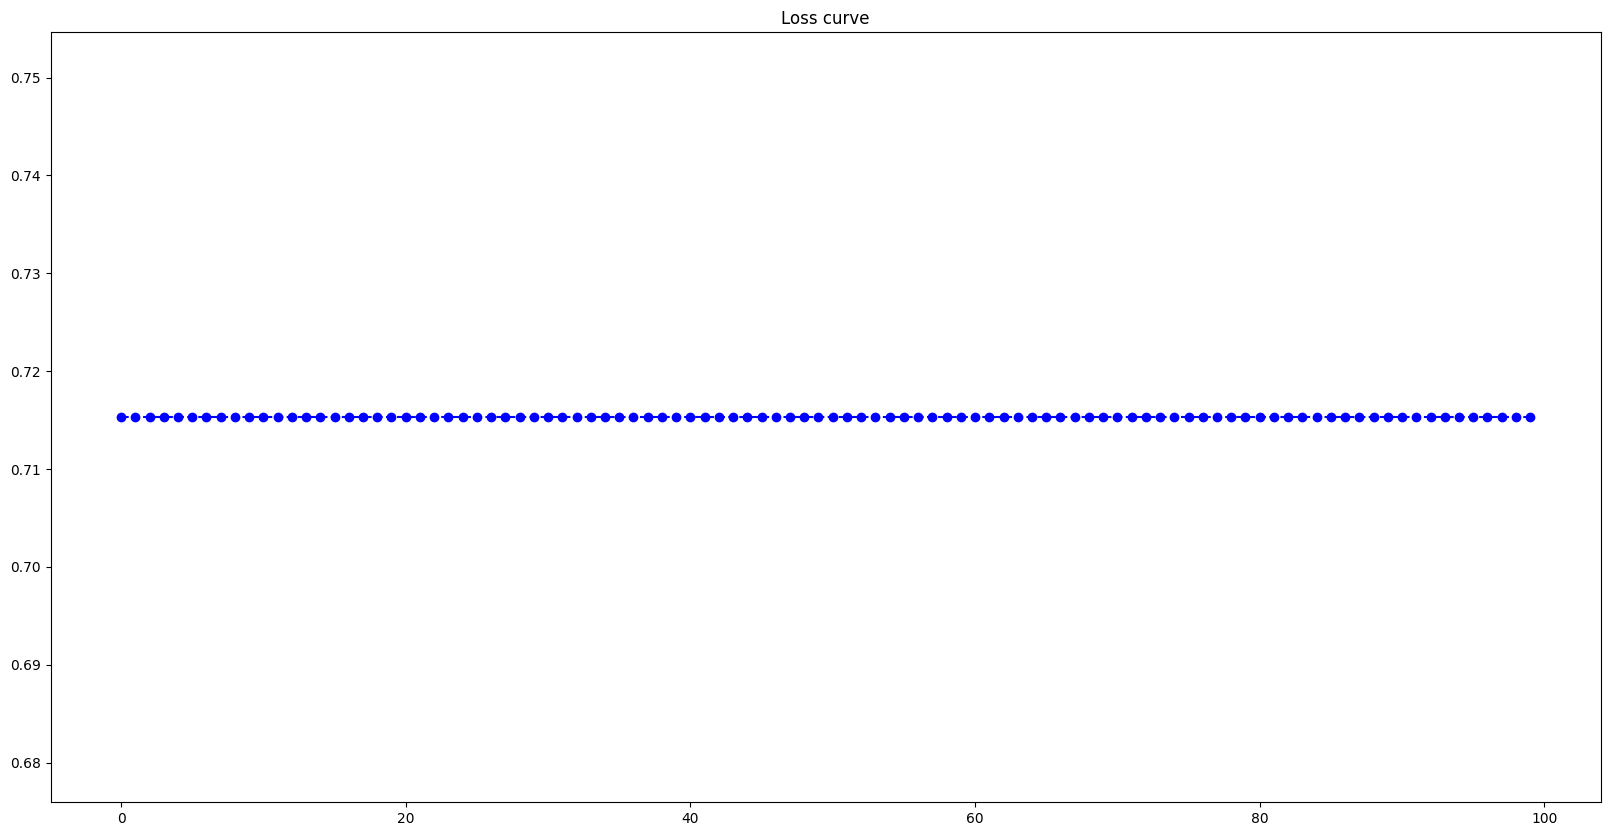

In [20]:
py = importlib.reload(py)

py.plot(epoch_value, loss_function, title="Loss curve")

In [21]:
import requests
from pathlib import Path 

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

from helper_functions import plot_predictions, plot_decision_boundary

helper_functions.py already exists, skipping download


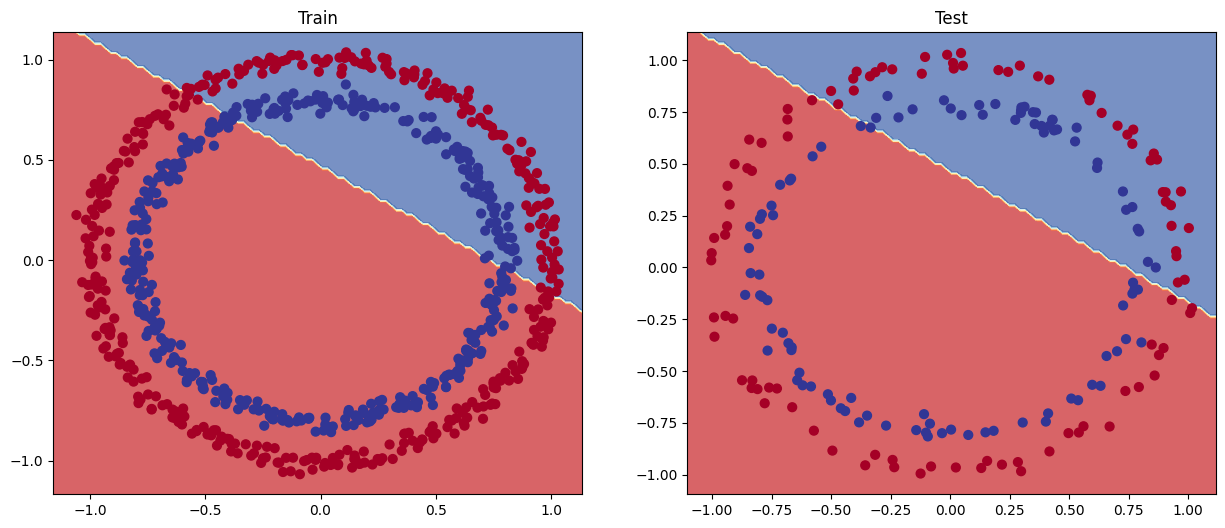

In [22]:
import matplotlib.pyplot as plt
def plot_db(model, x_train, y_train, x_test, y_test):
    plt.figure(figsize=(15, 6))
    plt.subplot(1, 2, 1)
    plot_decision_boundary(model, x_train, y_train)
    plt.title("Train")
    plt.subplot(1, 2, 2)
    plot_decision_boundary(model, x_test, y_test)
    plt.title("Test")

plot_db(model_one, train_features, train_label, test_features, test_label)

### **4. Update the Model**

In [23]:
py = importlib.reload(py)
model_1 = py.classification_model2()   #Updated model which have three layers and non linear activation function
model_1

classification_model2(
  (layer1): Linear(in_features=2, out_features=10, bias=True)
  (layer2): Linear(in_features=10, out_features=10, bias=True)
  (layer3): Linear(in_features=10, out_features=1, bias=True)
)

In [24]:
#create loss function
loss_fn_1 = nn.BCEWithLogitsLoss()

#create optimizer
optimizer_1 = torch.optim.SGD(model_1.parameters(), lr=0.01)

In [46]:
#now train the model with the same training loop as before but with new model, loss function and optimizer
epochs = 1000

#training loop
for epoch in range(epochs):    #100 iteration for training the model.
    model_1.train()   
    y_logits = model_1(train_features.to(device)).squeeze()  #forward pass
    loss = loss_fn_1(y_logits.squeeze(), train_label.type(torch.float32).to(device))           #calculate the loss
    optimizer_1.zero_grad()                                      #zero the gradients
    loss.backward()                                            #backward pass
    optimizer_1.step()                                           #update the weights

    #then testing loop
    model_1.eval()       #put the model in evaluation mode
    with torch.inference_mode(): #turn on inference mode (turn off gradients)
        test_logits = model_1(test_features.to(device)).squeeze()  #forward pass(prediction of test dataset)
        test_logits = (torch.sigmoid(test_logits)>=0.5).float()     #turn the logits to probability
        test_loss = loss_fn_1(test_logits.squeeze(), test_label.type(torch.float32).to(device)) #Calculate the loss funcion of test dataset
        test_acc = py.man_accuracy(test_label.to(device), test_logits.to(device))      #Calculate the accuracy of the model.
    if epoch % 100 == 0:
        print(f"Epoch: {epoch} |  Loss: {loss:.5f} |  Test Loss:  {test_loss:.5f} |  Test Accuracy: {test_acc}")        


Epoch: 0 |  Loss: 0.69305 |  Test Loss:  0.76181 |  Test Accuracy: 49.00%
Epoch: 100 |  Loss: 0.69303 |  Test Loss:  0.77181 |  Test Accuracy: 47.00%
Epoch: 200 |  Loss: 0.69302 |  Test Loss:  0.77801 |  Test Accuracy: 46.00%
Epoch: 300 |  Loss: 0.69301 |  Test Loss:  0.77611 |  Test Accuracy: 46.50%
Epoch: 400 |  Loss: 0.69301 |  Test Loss:  0.77231 |  Test Accuracy: 47.50%
Epoch: 500 |  Loss: 0.69300 |  Test Loss:  0.77731 |  Test Accuracy: 46.50%
Epoch: 600 |  Loss: 0.69300 |  Test Loss:  0.77421 |  Test Accuracy: 47.00%
Epoch: 700 |  Loss: 0.69299 |  Test Loss:  0.77421 |  Test Accuracy: 47.00%
Epoch: 800 |  Loss: 0.69299 |  Test Loss:  0.77611 |  Test Accuracy: 46.50%
Epoch: 900 |  Loss: 0.69299 |  Test Loss:  0.77491 |  Test Accuracy: 46.50%


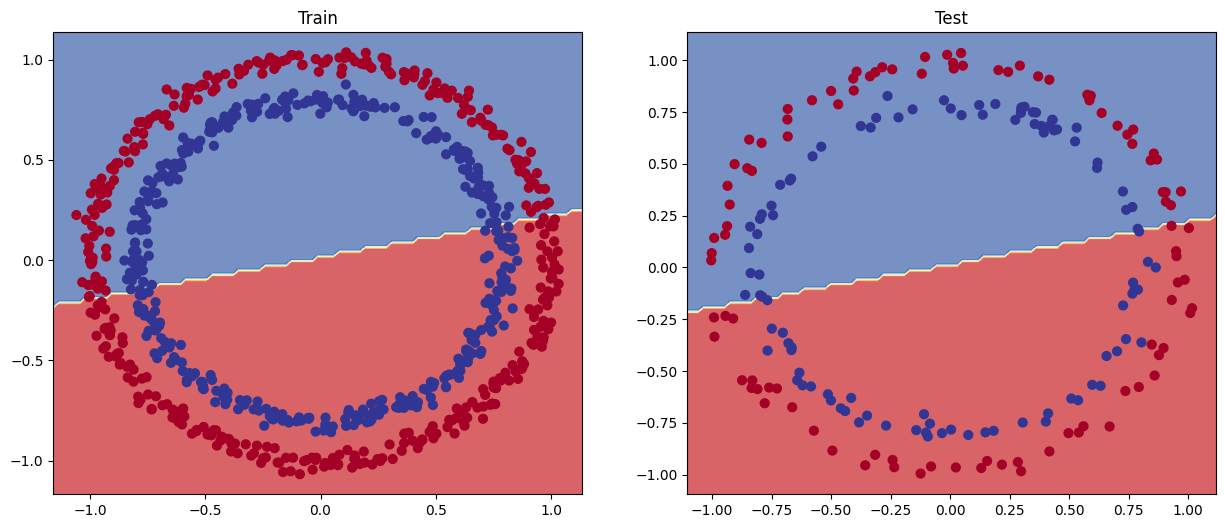

In [26]:
plot_db(model_1, train_features, train_label, test_features, test_label)   #But this is not correct still

Make linear data to see how our model are behave

tensor([0.0000, 0.0100, 0.0200, 0.0300, 0.0400]) tensor([0.2000, 0.2078, 0.2156, 0.2234, 0.2312])


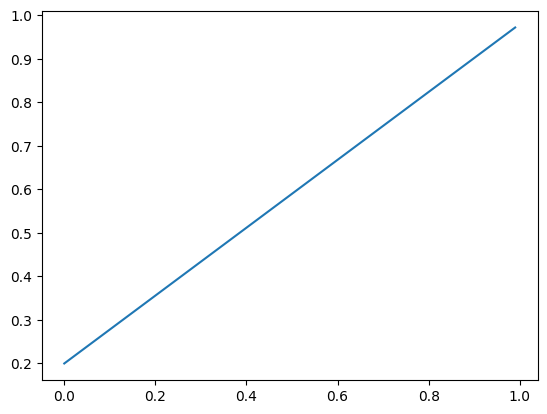

In [27]:
wight = 0.78
bias = 0.2
start = 0
end = 1
step = 0.01

x =torch.arange(start, end, step)
y = wight * x + bias
print(x[:5], y[:5])
plt.plot(x, y)

In [28]:
split_len = int(0.8 * len(x))
x_train, x_test = x[:split_len], x[split_len:]
y_train, y_test = y[:split_len], y[split_len:]
print(len(x_train), len(x_test), len(y_train), len(y_test))

80 20 80 20


In [29]:
type(x_train), type(y_train), x_train.shape, y_train.shape

(torch.Tensor, torch.Tensor, torch.Size([80]), torch.Size([80]))

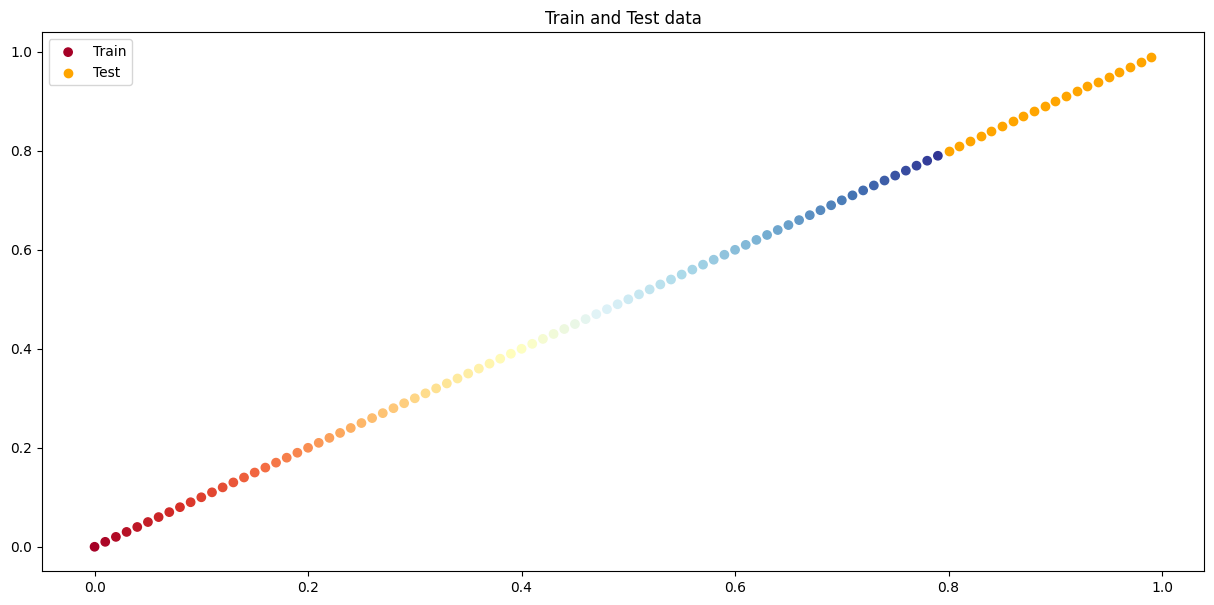

In [30]:
py = importlib.reload(py)
py.scatter_plot(x_train, y_train, x_test, y_test, title="Train and Test data")

In [31]:
#now define linear model for this data
lin_model =nn.Sequential(
    nn.Linear(in_features=1, out_features=10),
    nn.Linear(in_features=10, out_features=10),
    nn.Linear(in_features=10, out_features=1)
)

In [32]:
lin_loss_fn = nn.L1Loss()

lin_optimizer = torch.optim.SGD(lin_model.parameters(), lr=0.01) 

In [33]:
# Train the model
torch.manual_seed(42)

# Set the number of epochs
epochs = 1000

#to fix shape mismached  errror
x_train = x_train.unsqueeze(1)
x_test = x_test.unsqueeze(1)
y_train = y_train.unsqueeze(1)
y_test = y_test.unsqueeze(1)

# Put data to target device(if available)
for epoch in range(epochs):
    ### Training 
    lin_model.train()
    # 1. Forward pass
    y_pred = lin_model(x_train)
    
    # 2. Calculate loss (no accuracy since it's a regression problem, not classification)
    loss = lin_loss_fn(y_pred, y_train)

    # 3. Optimizer zero grad
    lin_optimizer.zero_grad()

    # 4. Loss backwards
    loss.backward()

    # 5. Optimizer step
    lin_optimizer.step()

    ### Testing
    lin_model.eval()
    with torch.inference_mode():
      # 1. Forward pass
      test_pred = lin_model(x_test)
      # 2. Calculate the loss 
      test_loss = lin_loss_fn(test_pred, y_test)

    # Print out what's happening
    if epoch % 100 == 0: 
        print(f"Epoch: {epoch} | Train loss: {loss:.5f}, Test loss: {test_loss:.5f}")

Epoch: 0 | Train loss: 0.51056, Test loss: 0.79433
Epoch: 100 | Train loss: 0.00900, Test loss: 0.01941
Epoch: 200 | Train loss: 0.01653, Test loss: 0.05979
Epoch: 300 | Train loss: 0.01667, Test loss: 0.06148
Epoch: 400 | Train loss: 0.01907, Test loss: 0.06066
Epoch: 500 | Train loss: 0.01873, Test loss: 0.06000
Epoch: 600 | Train loss: 0.01815, Test loss: 0.05725
Epoch: 700 | Train loss: 0.01797, Test loss: 0.05624
Epoch: 800 | Train loss: 0.01760, Test loss: 0.05646
Epoch: 900 | Train loss: 0.01689, Test loss: 0.05475


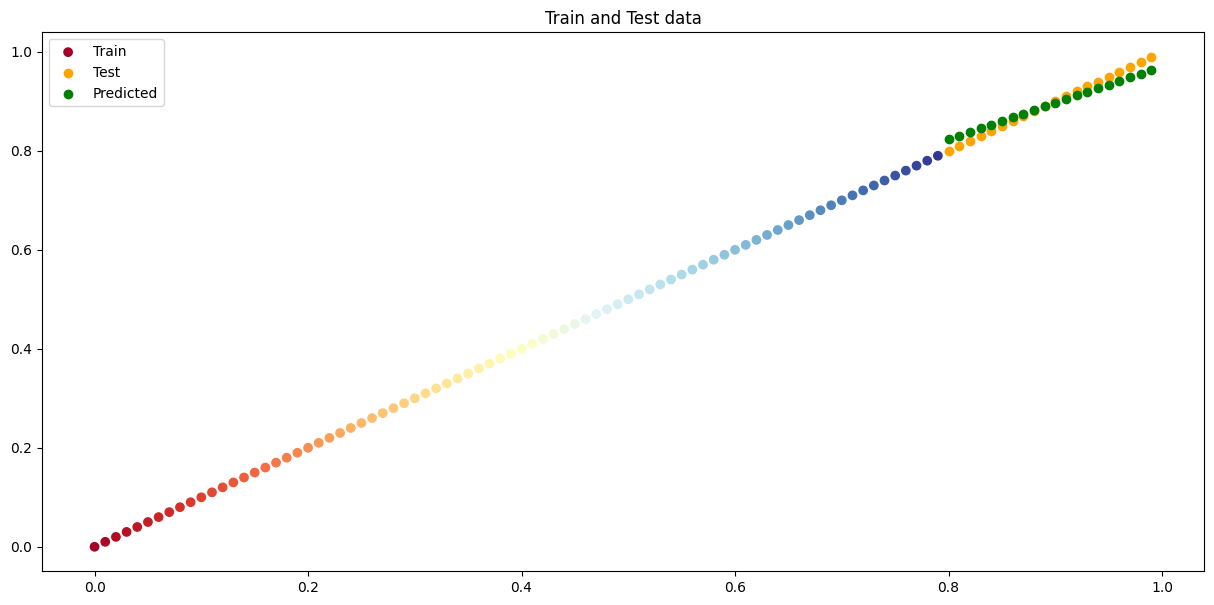

In [34]:
py = importlib.reload(py)
lin_model.eval()
with torch.inference_mode():
    test_pred = lin_model(x_test)
    test_loss = lin_loss_fn(test_pred, y_test)
py.scatter_plot(x_train, y_train, x_test, y_test, test_pred, title="Train and Test data")

In [35]:
# Build model with non-linear activation function
from torch import nn
class CircleModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10)
        self.layer_3 = nn.Linear(in_features=10, out_features=1)
        self.relu = nn.ReLU() # <- add in ReLU activation function
        # Can also put sigmoid in the model 
        # This would mean you don't need to use it on the predictions
        # self.sigmoid = nn.Sigmoid()

    def forward(self, x):
      # Intersperse the ReLU activation function between layers
       return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

model_3 = CircleModelV2().to(device)
print(model_3)

CircleModelV2(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)


In [61]:
y_logits = model_3(train_features.to(device))
print(train_label.shape, y_logits.squeeze().shape)
print(y_logits.dtype, train_label.type(torch.float32).dtype)

torch.Size([800]) torch.Size([800])
torch.float32 torch.float32


In [91]:
# Fit the model
py = importlib.reload(py)

torch.manual_seed(42)
epochs = 1000
epoch_value = []
loss_function = []

loss_fn_3 = nn.BCEWithLogitsLoss()
optimizer_3 = torch.optim.SGD(model_3.parameters(), lr=0.1)

for epoch in range(epochs):
    # 1. Forward pass
    model_3.train()
    y_logits = model_3(train_features.to(device)).squeeze()

    # 2. Calculate loss and accuracy
    loss = loss_fn_3(y_logits, train_label.type(torch.float32).to(device))
    train_accu = py.man_accuracy(y_true=train_label,   y_pred=y_logits)
    
    # 3. Optimizer zero grad
    optimizer_3.zero_grad()

    # 4. Loss backward    
    loss.backward()

    # 5. Optimizer step
    optimizer_3.step()
    epoch_value.append(epoch)
    loss_function.append(loss.item())

    ### Testing
    model_3.eval()
    with torch.inference_mode():
      # 1. Forward pass
      test_logits = model_3(test_features.to(device)).squeeze()
      y_test_pred = torch.round(torch.sigmoid(test_logits))         # logits -> prediction probabilities -> prediction labels  

      test_loss = loss_fn_3(test_logits, test_label.type(torch.float32).to(device))

      test_acc = py.man_accuracy(y_true=test_label.to(device), y_pred=y_test_pred)

    # Print out what's happening
    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}| Train Accuracy: {train_accu}% | Test Loss: {test_loss:.5f}, Test Accuracy: {test_acc}%")

Epoch: 0 | Loss: 0.00885| Train Accuracy: 100.00%% | Test Loss: 0.02181, Test Accuracy: 99.50%%
Epoch: 100 | Loss: 0.00858| Train Accuracy: 100.00%% | Test Loss: 0.02138, Test Accuracy: 99.50%%
Epoch: 200 | Loss: 0.00833| Train Accuracy: 100.00%% | Test Loss: 0.02094, Test Accuracy: 99.50%%
Epoch: 300 | Loss: 0.00809| Train Accuracy: 100.00%% | Test Loss: 0.02053, Test Accuracy: 99.50%%
Epoch: 400 | Loss: 0.00787| Train Accuracy: 100.00%% | Test Loss: 0.02015, Test Accuracy: 99.50%%
Epoch: 500 | Loss: 0.00765| Train Accuracy: 100.00%% | Test Loss: 0.01993, Test Accuracy: 99.50%%
Epoch: 600 | Loss: 0.00745| Train Accuracy: 100.00%% | Test Loss: 0.01962, Test Accuracy: 99.50%%
Epoch: 700 | Loss: 0.00726| Train Accuracy: 100.00%% | Test Loss: 0.01928, Test Accuracy: 99.50%%
Epoch: 800 | Loss: 0.00708| Train Accuracy: 100.00%% | Test Loss: 0.01896, Test Accuracy: 99.50%%
Epoch: 900 | Loss: 0.00690| Train Accuracy: 100.00%% | Test Loss: 0.01866, Test Accuracy: 99.50%%


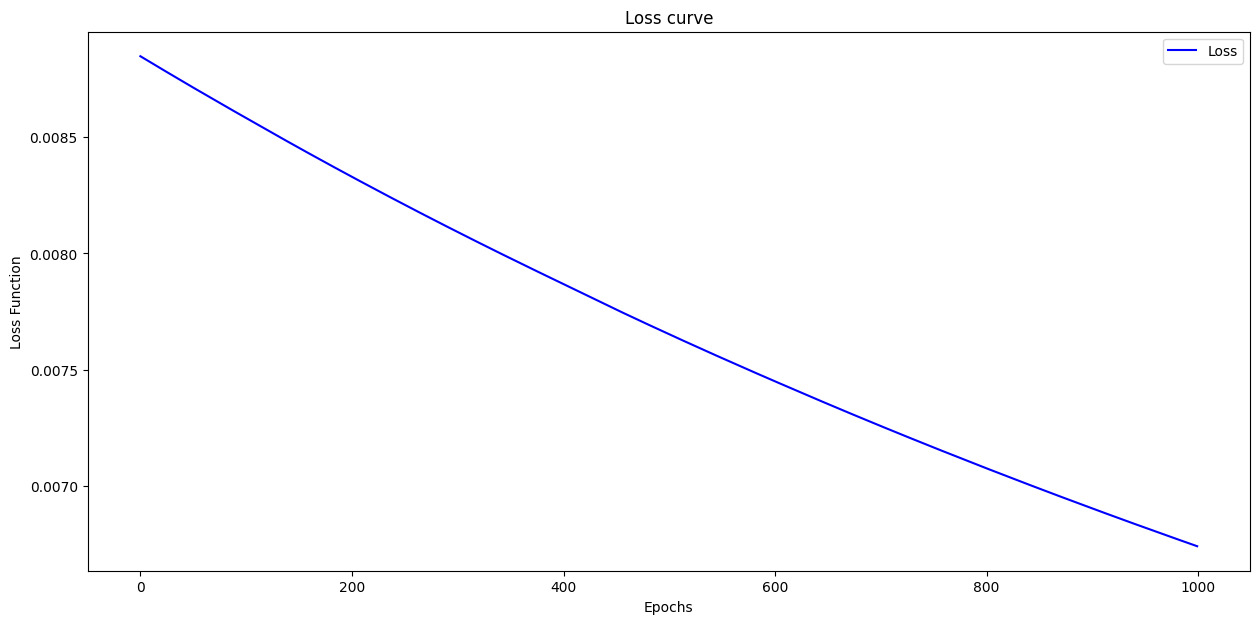

In [107]:
plt.figure(figsize=(15, 7))
plt.plot(epoch_value, loss_function, label="Loss", color="blue")
plt.title("Loss curve")
plt.xlabel("Epochs")
plt.ylabel("Loss Function")
plt.legend()
plt.show()

### **5. Build a model with non linear data**

In [81]:
#Define  the model with non linear activation function and more layers
from torch import nn
class CircleModelV3(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10)
        self.layer_3 = nn.Linear(in_features=10, out_features=1)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

In [82]:
#now define loss function and the optimizer for the model
import torch

#initialize the model
circle_model = CircleModelV3()

#define loss finction
cir_loss_fn = nn.BCEWithLogitsLoss()

#define optimizer
cir_optimizer = torch.optim.SGD(circle_model.parameters(), lr=0.01)

**Make Circle dataset**

In [83]:
#Create circular data
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split

n_samples = 1000

X, Y = make_circles(n_samples=1000,
    noise=0.03,
    random_state=42,
)
#Change the data from numpy to tensor
X_tesnor, Y_tensor = torch.from_numpy(X).type(torch.float32), torch.from_numpy(Y).type(torch.float32)

#Then spit the data into train and test part
x_train_c, x_test_c, y_train_c,  y_test_c  =train_test_split(X_tesnor, Y_tensor, test_size=0.2, random_state=42)

In [112]:
#Train the model using train and test loop
py = importlib.reload(py)

torch.manual_seed(42)
epochs = 1000

for epoch in range(epochs):
    # Training /forward pass
    circle_model.train()

    #prediction and loss
    y_logits = circle_model(x_train_c).squeeze()

    #Calculate the loss function and train accuracy
    loss = cir_loss_fn(y_logits, y_train_c.type(torch.float32))
    train_accuracy = py.man_accuracy(y_train_c, y_logits)

    #optimizer zero grad
    cir_optimizer.zero_grad()

    #Backward pass
    loss.backward()

    #Update the weights
    cir_optimizer.step()

    # Testing
    circle_model.eval()
    with torch.inference_mode():
        test_logits = circle_model(x_test_c).squeeze()
        test_loss = cir_loss_fn(test_logits, y_test_c.type(torch.float32))
        accuracy = py.man_accuracy(y_test_c, test_logits)
    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}|Train accu: {train_accu} | Test Loss: {test_loss:.5f} | Accuracy: {accuracy}%")

Epoch: 0 | Loss: 0.68515|Train accu: 100.00% | Test Loss: 0.68413 | Accuracy: 56.50%%
Epoch: 100 | Loss: 0.68479|Train accu: 100.00% | Test Loss: 0.68375 | Accuracy: 56.50%%
Epoch: 200 | Loss: 0.68442|Train accu: 100.00% | Test Loss: 0.68334 | Accuracy: 56.00%%
Epoch: 300 | Loss: 0.68404|Train accu: 100.00% | Test Loss: 0.68291 | Accuracy: 56.00%%
Epoch: 400 | Loss: 0.68365|Train accu: 100.00% | Test Loss: 0.68247 | Accuracy: 56.00%%
Epoch: 500 | Loss: 0.68324|Train accu: 100.00% | Test Loss: 0.68200 | Accuracy: 56.00%%
Epoch: 600 | Loss: 0.68282|Train accu: 100.00% | Test Loss: 0.68152 | Accuracy: 56.00%%
Epoch: 700 | Loss: 0.68239|Train accu: 100.00% | Test Loss: 0.68103 | Accuracy: 56.50%%
Epoch: 800 | Loss: 0.68193|Train accu: 100.00% | Test Loss: 0.68051 | Accuracy: 56.50%%
Epoch: 900 | Loss: 0.68148|Train accu: 100.00% | Test Loss: 0.67998 | Accuracy: 56.00%%


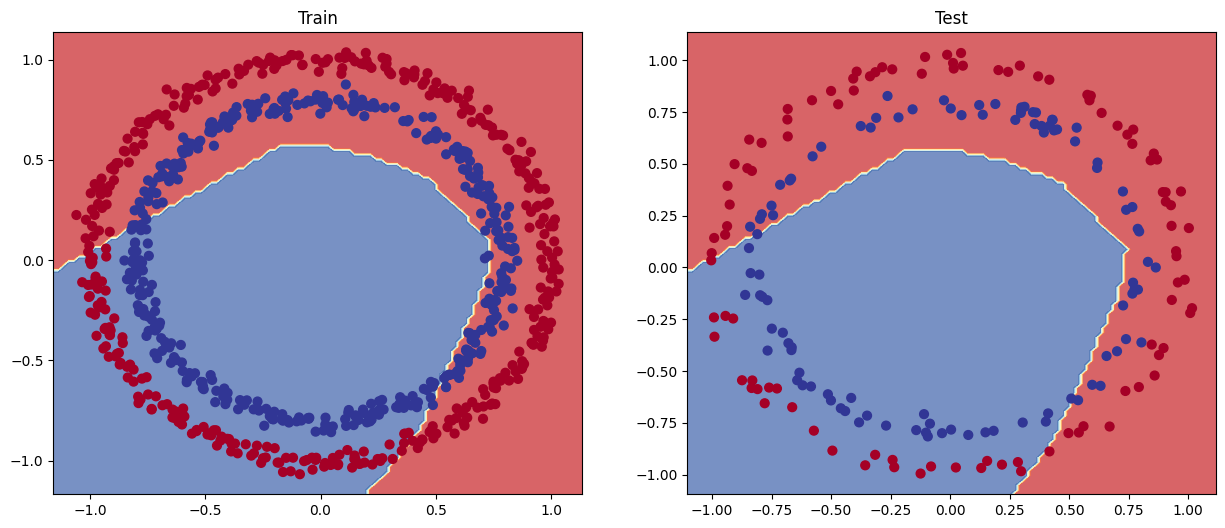

In [114]:
plot_db(circle_model, x_train_c, y_train_c, x_test_c, y_test_c)

### **6. Multi Class Classification**

In [130]:
#create multiclass data from sklearn library(make_blobs)
from sklearn.datasets import make_blobs

#change the tuple to numpy array
x_data, y_data = make_blobs(
    n_samples=1000,
    n_features=2,
    centers=4,
    random_state=42,
    cluster_std=1.5
)

#Change numpy array to tensor
x_blob_tensor = torch.from_numpy(x_data).float()
y_blob_tensor = torch.from_numpy(y_data).float()

#now train test split 
x_train_b, x_test_b, y_train_b, y_test_b = train_test_split(x_blob_tensor, y_blob_tensor, test_size=0.2, random_state=42)

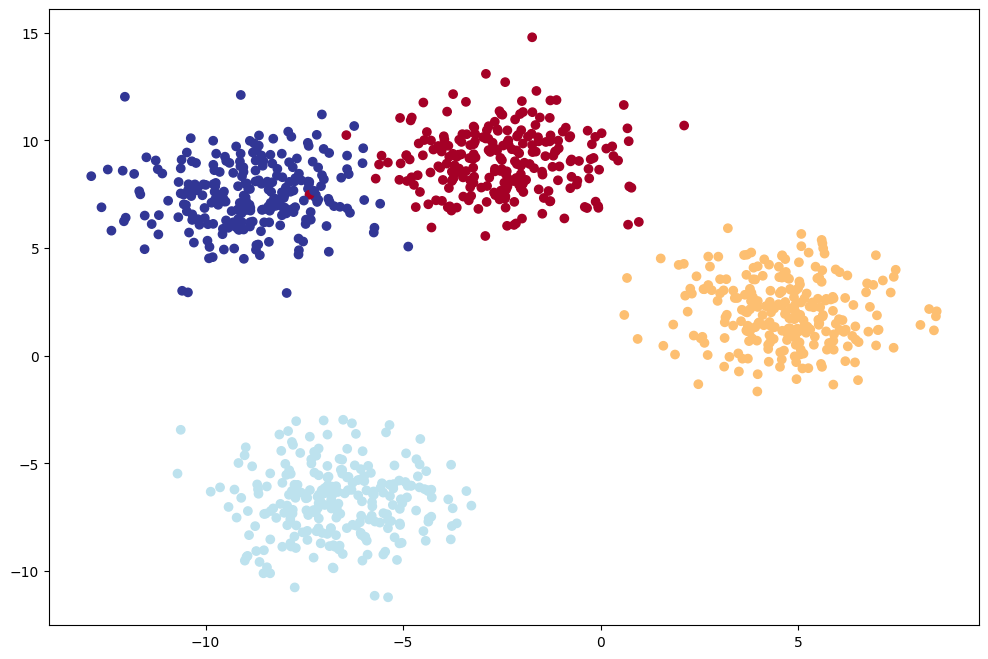

In [134]:
plt.figure(figsize=(12, 8))
plt.scatter(x_data[:, 0],x_data[:, 1], c=y_data, cmap=plt.cm.RdYlBu)

In [139]:
#define the model 
class multiclassModel(nn.Module):
    def __init__(self, input_feature, output_feaeture, hidden_unit=8):
        super().__init__()
        self.linear_layers = nn.Sequential(
            nn.Linear(in_features=input_feature, out_features=hidden_unit),
            # nn.ReLU(),
            nn.Linear(in_features=hidden_unit, out_features=hidden_unit),
            # nn.ReLU(),
            nn.Linear(in_features=hidden_unit, out_features=output_feaeture)
        )
    def forward(self, x):
        return self.linear_layers(x)
blobModel = multiclassModel(input_feature=2, output_feaeture=4, hidden_unit=8)
blobModel

multiclassModel(
  (linear_layers): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): Linear(in_features=8, out_features=8, bias=True)
    (2): Linear(in_features=8, out_features=4, bias=True)
  )
)

In [140]:
#define loss function and optimizer
blob_loss_fn = nn.CrossEntropyLoss()
blob_optimizer = torch.optim.SGD(blobModel.parameters(), lr=0.01)

In [150]:
#make prediction

blob_pred = blobModel(x_train_b[:5])
x_train_b[:5], blob_pred

(tensor([[ 5.0405,  3.3076],
         [-2.6249,  9.5260],
         [-8.5240, -9.0402],
         [-6.0262, -4.4375],
         [-3.3397,  7.2175]]),
 tensor([[-0.3915, -0.9628,  0.6262,  0.4157],
         [-1.5593, -0.4880, -0.7083, -0.7420],
         [ 1.0770,  1.0126, -1.4596, -0.0068],
         [ 0.4540,  0.5356, -1.1030, -0.0912],
         [-1.2309, -0.3033, -0.7986, -0.6488]], grad_fn=<AddmmBackward0>))

In [153]:
#we use softmax function to turn the logit to probability

mult_predi_pro = torch.softmax(blob_pred, dim=1)
mult_predi_pro, blob_pred, torch.sum(mult_predi_pro, dim=1)

(tensor([[0.1521, 0.0859, 0.4209, 0.3410],
         [0.1173, 0.3424, 0.2747, 0.2656],
         [0.4246, 0.3981, 0.0336, 0.1436],
         [0.3478, 0.3773, 0.0733, 0.2016],
         [0.1458, 0.3686, 0.2246, 0.2609]], grad_fn=<SoftmaxBackward0>),
 tensor([[-0.3915, -0.9628,  0.6262,  0.4157],
         [-1.5593, -0.4880, -0.7083, -0.7420],
         [ 1.0770,  1.0126, -1.4596, -0.0068],
         [ 0.4540,  0.5356, -1.1030, -0.0912],
         [-1.2309, -0.3033, -0.7986, -0.6488]], grad_fn=<AddmmBackward0>),
 tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000], grad_fn=<SumBackward1>))

In [156]:
print(y_train_b.shape)

torch.Size([800])


In [160]:
#then training and testing loop


torch.manual_seed(42)

epoch_value = []
loss_mul_fn = []

epochs =1000

for epoch in range(epochs):
    #training loop
    blobModel.train()
    y_logits = blobModel(x_train_b).squeeze()
    loss = blob_loss_fn(y_logits, y_train_b.type(torch.long))
    blob_optimizer.zero_grad()
    loss.backward()
    blob_optimizer.step()

    #testing loop
    blobModel.eval()
    with torch.inference_mode():
        test_logits = blobModel(x_test_b).squeeze()
        test_loss = blob_loss_fn(test_logits, y_test_b.type(torch.long))
    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f} | Test Loss: {test_loss:.5f} |")
    epoch_value.append(epoch)
    loss_mul_fn.append(loss.item())

Epoch: 0 | Loss: 0.02918 | Test Loss: 0.01946 |
Epoch: 100 | Loss: 0.02894 | Test Loss: 0.01913 |
Epoch: 200 | Loss: 0.02872 | Test Loss: 0.01884 |
Epoch: 300 | Loss: 0.02853 | Test Loss: 0.01857 |
Epoch: 400 | Loss: 0.02835 | Test Loss: 0.01832 |
Epoch: 500 | Loss: 0.02819 | Test Loss: 0.01809 |
Epoch: 600 | Loss: 0.02804 | Test Loss: 0.01788 |
Epoch: 700 | Loss: 0.02790 | Test Loss: 0.01768 |
Epoch: 800 | Loss: 0.02778 | Test Loss: 0.01750 |
Epoch: 900 | Loss: 0.02766 | Test Loss: 0.01732 |


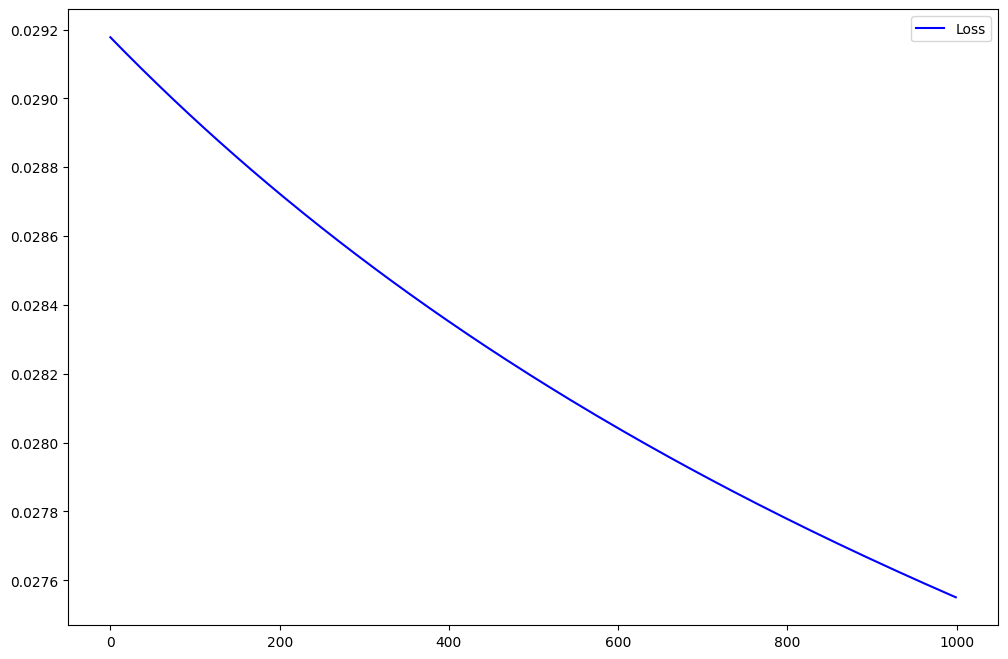

In [163]:
plt.figure(figsize=(12, 8))
plt.plot(epoch_value, loss_mul_fn, label="Loss", color="blue")
plt.legend()
plt.show()

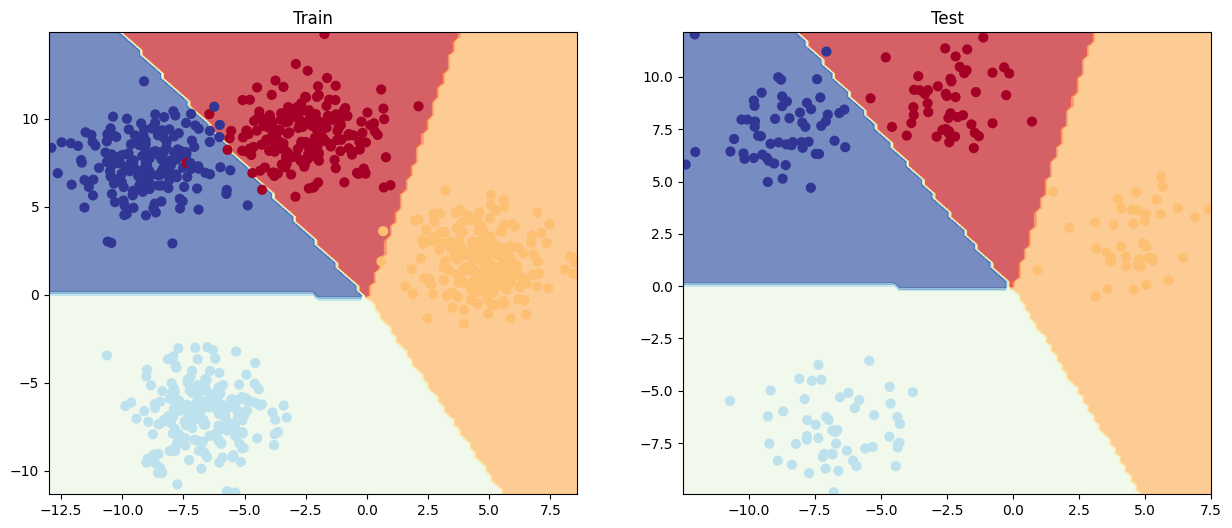

In [165]:
plot_db(blobModel, x_train_b, y_train_b, x_test_b, y_test_b)